In [1]:
'''
inspect new science extractions april 2026
'''

'\ninspect new science extractions april 2026\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner


In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [15]:
onelist = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020163819_000640_zg_c02_x_0025._4_alllist')#, allow_pickle=True)

In [16]:
onelist

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quad
0,0,ztf_20221020163819_000640_zg_c02_x_0025.,pos,28.000000,2605.000000,1,4
1,1,ztf_20221020163819_000640_zg_c02_x_0025.,pos,28.000000,2607.000000,1,4
2,2,ztf_20221020163819_000640_zg_c02_x_0025.,pos,250.500000,220.000000,2,4
3,3,ztf_20221020163819_000640_zg_c02_x_0025.,pos,250.000000,223.000000,3,4
4,4,ztf_20221020163819_000640_zg_c02_x_0025.,pos,393.500000,2989.000000,2,4
5,5,ztf_20221020163819_000640_zg_c02_x_0025.,pos,424.000000,2517.500000,4,4
6,6,ztf_20221020163819_000640_zg_c02_x_0025.,pos,426.000000,2516.000000,1,4
7,7,ztf_20221020163819_000640_zg_c02_x_0025.,pos,426.000000,2518.000000,1,4
8,8,ztf_20221020163819_000640_zg_c02_x_0025.,pos,427.000000,2369.000000,1,4
9,9,ztf_20221020163819_000640_zg_c02_x_0025.,pos,434.000000,1460.000000,1,4


In [53]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [54]:
fpath_extractions_saveds = [
        "/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/"]


for fpath_extractions_saved in fpath_extractions_saveds: 
    wid = 10
    abst_thr = .99
    
    files = [f for f in os.listdir(fpath_extractions_saved) if f.endswith("predsarray.npy")] 
    for i, file in enumerate(files):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        quad = image_filename[-16]
        path_to_save = fpath_extractions_saved+str(filename_start)+'_'+quad+'_alllist'
        
        if os.path.isfile( #if the one we want to make already exists
            path_to_save
        ):
            print("skipping ", filename_start)
            continue

        print(file)

        try: 
            predsarray = np.load(fpath_extractions_saved+image_filename, allow_pickle=True)
        except: #
            print("didn't load")
            print(fpath_extractions_saved+image_filename)
            continue

        alllist = rff.make_obj_list(predsarray, abst_thr, filename_start, quad)

        if alllist)!=NoneType:
            alllist.to_csv(path_to_save)
        del predsarray
        del alllist
        gc.collect()

skipping  ztf_20221020148032_000686_zg_c07_x_0000.
skipping  ztf_20221020157697_000640_zi_c12_x_0011.
skipping  ztf_20221020148032_000686_zg_c01_x_0017.
skipping  ztf_20221020163819_000640_zg_c02_x_0025.
skipping  ztf_20221020163819_000640_zg_c09_x_0020.
skipping  ztf_20221020154120_000640_zi_c12_x_0004.
skipping  ztf_20221020154120_000640_zi_c10_x_0018.
skipping  ztf_20221020141806_000686_zi_c09_x_0021.
ztf_20221020294271_000449_zr_c09_x_0002._extraction_predsarray_2_predsarray.npy
NO DETECTIONS IN THIS FILE


In [62]:
type(alllist)==pd.DataFrame

False

In [38]:
fname = filename_start
if 1==1:
    nrow, ncol = 3080, 3072
    wid=10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    # pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    # pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_sat = predsarray[:, 5].reshape(ncol - 2 * wid, nrow - 2 * wid)

    # pimg_both = pimg_pos + pimg_neg

    structure = [[1, 1, 1], [1, 1, 1], [1, 1, 1]]  # for what counts as one object

    # FOR POS
    thrdet = pimg_pos > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_pos = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_pos = np.array(loc_list_pos)
    objsizes_pos = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_pos), fname)
    poses = np.full(len(loc_list_pos), "pos")
    if len(loc_list_pos) > 0:
        poslist = (
            np.vstack(
                (fnames, poses, loc_list_pos[:, 0], loc_list_pos[:, 1], objsizes_pos)
            )
        ).T
    else:
        poslist = 0

    # FOR NEG
    thrdet = pimg_neg > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_neg = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_neg = np.array(loc_list_neg)

    objsizes_neg = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_neg), fname)
    negs = np.full(len(loc_list_neg), "neg")

    if len(loc_list_neg) > 0:
        neglist = (
            np.vstack(
                (fnames, negs, loc_list_neg[:, 0], loc_list_neg[:, 1], objsizes_neg)
            )
        ).T
    else:
        neglist = 0
    # FOR CRS
    thrdet = pimg_cr > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_cr = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_cr = np.array(loc_list_cr)

    objsizes_cr = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_cr), fname)
    if len(loc_list_cr) > 0:
        crs = np.full(len(loc_list_cr), "cr")
        # print(np.shape(fnames))
        # print(np.shape(crs))
        # print(np.shape(loc_list_cr[:,0]))
        # print(np.shape(loc_list_cr[:,1]))
        # print(np.shape(objsizes_cr))
        crlist = (
            np.vstack((fnames, crs, loc_list_cr[:, 0], loc_list_cr[:, 1], objsizes_cr))
        ).T
    else:
        crlist = 0
#     # FOR BOTH
#     thrdet = pimg_both > abst_thr
#     threshed = thrdet.T  # it takes the transposed pimg

#     labs, nlabs = snm.label(threshed, structure)
#     loc_list_both = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
#     loc_list_both = np.array(loc_list_both)

#     objsizes_both = pr.get_objsizes(labs, nlabs)

#     fnames = np.full(len(loc_list_both), fname)
#     boths = np.full(len(loc_list_both), "both")
#     if len(loc_list_both) > 0:
#         bothlist = (
#             np.vstack(
#                 (fnames, boths, loc_list_both[:, 0], loc_list_both[:, 1], objsizes_both)
#             )
#         ).T
    thrdet = pimg_sat > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_sat = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_sat = np.array(loc_list_sat)

    objsizes_sat = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_sat), fname)
    if len(loc_list_sat) > 0:
        sats = np.full(len(loc_list_sats), "sat")
        # print(np.shape(fnames))
        # print(np.shape(crs))
        # print(np.shape(loc_list_cr[:,0]))
        # print(np.shape(loc_list_cr[:,1]))
        # print(np.shape(objsizes_cr))
        satlist = (
            np.vstack((fnames, sats, loc_list_sat[:, 0], loc_list_sat[:, 1], objsizes_sat))
        ).T
    else:
        satlist = 0

    # del pimg_cr
    # del pimg_pos
    # del pimg_neg
    # # del pimg_bg
    # del pimg_sat
    # del thrdet
    # del loc_list_pos
    # del loc_list_neg
    # del objsizes_pos
    # del objsizes_neg
    # del labs
    # del threshed
    gc.collect()

    # np.save(path, n_loc_size_ray_b)
    if isinstance(poslist, np.ndarray):
        listlist = poslist
        for listype in [neglist, crlist, satlist]:
        if isinstance(listype, np.ndarray):
            listlist = np.vstack((listlist, listype))
        alllist = pd.DataFrame(listlist)
    elif isinstance(neglist, np.ndarray):
        listlist = neglist
        for listype in [poslist, crlist, satlist]:
        if isinstance(listype, np.ndarray):
            listlist = np.vstack((listlist, listype))
        alllist = pd.DataFrame(listlist)
    else:
        print("NO DETECTIONS IN THIS FILE")
        alllist = None
    # if isinstance(crlist, np.ndarray) & isinstance(satlist, np.ndarray):
    #     listlist = np.vstack((poslist, neglist, crlist, satlist))
    # # else:
    #     # if isinstance(neglist, np.ndarray):
    # elif isinstance(crlist, np.ndarray):
    #     listlist = np.vstack((poslist, neglist, crlist))
    # elif isinstance(satlist, np.ndarray):
    #     listlist = np.vstack((poslist, neglist, satlist))
    # else: # not isinstance(crlist, np.ndarray) & not isinstance(satlist, np.ndarray):
    #         listlist = np.vstack((poslist, neglist))
    # # else:
    #     print("help im having problems")
    

In [39]:
loc_list_pos

array([], dtype=float64)

In [45]:
np.max(predsarray[:,1])

0.9830219

In [49]:
np.sum(predsarray[:,3]>.99)

0

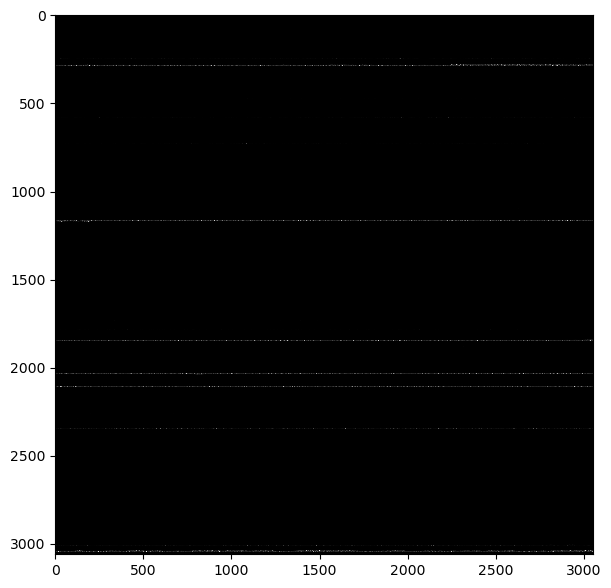

In [30]:
plt.imshow(predsarray[:,1].reshape(3060,3052))

In [14]:
pd.read_csv(path_to_save)

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quad
0,0,ztf_20221020148032_000686_zg_c07_x_0000.,pos,42.933333,620.866667,45,1
1,1,ztf_20221020148032_000686_zg_c07_x_0000.,pos,50.153846,930.365385,52,1
2,2,ztf_20221020148032_000686_zg_c07_x_0000.,pos,81.307692,1717.038462,26,1
3,3,ztf_20221020148032_000686_zg_c07_x_0000.,pos,224.066667,1716.666667,15,1
4,4,ztf_20221020148032_000686_zg_c07_x_0000.,pos,248.500000,2911.000000,2,1
...,...,...,...,...,...,...,...
77,77,ztf_20221020148032_000686_zg_c07_x_0000.,neg,2100.800000,1657.700000,10,1
78,78,ztf_20221020148032_000686_zg_c07_x_0000.,neg,2300.500000,1714.000000,2,1
79,79,ztf_20221020148032_000686_zg_c07_x_0000.,neg,2301.000000,1716.500000,2,1
80,80,ztf_20221020148032_000686_zg_c07_x_0000.,neg,2323.000000,1357.000000,1,1


In [29]:
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/"

df_detections = pd.DataFrame([])
counter = 0
# # List all the files in the folder
files = [f for f in os.listdir(folder_path) if f.endswith('alllist')]  # Adjust this to your file format
for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))
    
# #pos
    # df_nocr = df[df["type"] != "cr"]
    # df_noboth = df_nocr[df_nocr["type"] != "both"]
    # df_reduced_edges= rff.reduce_edges(df_noboth, 15)
    
    quad = file[-9] #41
    newpath = folder_path
    
    xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
    xy_file = xy_path+file[:-15]+quad+".fits"
    
    data_list = []
    
    
    # closest_amounts_c = []
    with fits.open(xy_file) as hdul_xy:
        for i, rrow in df_reduced_edges.iterrows():
            col = rrow["col_from_nn"]
            target_x = col+10
        # print(xy_file)
            data = hdul_xy[1].data  
            stored_x = data["X"][:25]  # Column "X"
            stored_y = data["Y"][:25]
            closest_idx = np.argmin(np.abs(stored_x - target_x))
            closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
            if np.abs(closest_x-target_x)<=10:
                # plt.imshow(np.sqrt(file1_array[(int(closest_y))-20:(int(closest_y))+20, (int(closest_x))-20:(int(closest_x))+20]))
                # plt.scatter(20,20)
                # plt.show()    
                    # Retrieve the closest (x, y) match
                data_list.append({"filename": rrow["filename"], "quad":quad, "type":rrow["type"],"row_from_nn":rrow["row_from_nn"],  
                                  "col_from_nn":rrow["col_from_nn"], "detection_size":rrow["detection_size"],
                                 "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x)})
                dframe = pd.DataFrame(data_list)
                # dframe.to_csv(newpath+file+"_matched_corrected")
                
    # break

Number of transient candidates reduced from 12 to 10.


In [30]:
dframe

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
0,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,220.0,1781.000000,1,1793.0,2918.0,2.000000
1,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,220.0,1783.500000,2,1793.0,2918.0,0.500000
2,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,1142.0,230.500000,8,241.0,1629.0,0.500000
3,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,1498.0,1784.000000,1,1793.0,2918.0,1.000000
4,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,1498.0,1786.000000,1,1793.0,2918.0,3.000000
5,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,2351.0,231.166667,12,241.0,1629.0,0.166667
6,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,2444.0,231.000000,3,241.0,1629.0,0.000000
7,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,2584.5,1784.000000,10,1793.0,2918.0,1.000000
8,ztf_20221020154120_000640_zi_c05_x_0015.,2,pos,2935.5,233.000000,2,241.0,1629.0,2.000000
9,ztf_20221020154120_000640_zi_c05_x_0015.,2,neg,845.0,1781.000000,1,1793.0,2918.0,2.000000


In [33]:
'ztf_20221020154120_000640_zi_c05_x_0015._2_alllist'[-9]

'2'

In [23]:
quad

'2'

In [24]:
file

'ztf_20221020154120_000640_zi_c05_x_0015._2_alllist'

In [43]:
alllist = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020163819_000640_zg_c11_x_0014._4_alllist')

In [45]:
np.unique(alllist['type'], return_counts=True)

(array(['neg', 'pos'], dtype=object), array([ 4, 31]))

In [46]:
np.unique(matched['type'], return_counts=True)

(array(['neg', 'pos'], dtype=object), array([ 3, 31]))

In [26]:
matched = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020163819_000640_zg_c11_x_0014._4_alllist_matched')

In [47]:
alllist[alllist['type']=='neg']

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quad
31,31,ztf_20221020163819_000640_zg_c11_x_0014.,neg,454.0,1873.0,3,4
32,32,ztf_20221020163819_000640_zg_c11_x_0014.,neg,791.8,811.2,5,4
33,33,ztf_20221020163819_000640_zg_c11_x_0014.,neg,996.5,1360.0,2,4
34,34,ztf_20221020163819_000640_zg_c11_x_0014.,neg,2402.0,1288.0,1,4


In [48]:
matched[matched['type']=='neg']

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
31,31,ztf_20221020163819_000640_zg_c11_x_0014.,4,neg,791.8,811.2,5,821.0,101.0,0.2
32,32,ztf_20221020163819_000640_zg_c11_x_0014.,4,neg,996.5,1360.0,2,1371.0,703.0,1.0
33,33,ztf_20221020163819_000640_zg_c11_x_0014.,4,neg,2402.0,1288.0,1,1296.0,1432.0,2.0


In [58]:
concatsob = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [59]:
concatsob

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,sobel_ratio,sobels_x,sobels_y,quadrant,num_in_file_in_star
0,0,0,0,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,34.000000,1752.000000,15,1760.0,1586.0,2.000000,15.335986,[[-1.88607025e+01 2.60816956e+00 1.07009277e...,[[-6.60966492e+00 -1.33075104e+01 -2.56719971e...,4,9.0
1,1,1,1,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,43.960000,186.600000,25,195.0,1398.0,1.600000,12.280559,[[ 9.504593 18.13031 21.489899 -...,[[ 1.06905670e+01 9.85134888e+00 3.16265869e...,4,1.0
2,2,2,2,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,140.875000,2482.000000,8,2492.0,1589.0,0.000000,10.913323,[[-1.14753723e+00 -4.11605835e-01 3.91306458e...,[[-1.15688629e+01 -8.30720520e+00 -1.83418274e...,4,38.0
3,3,3,3,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,177.500000,2481.875000,8,2492.0,1589.0,0.125000,23.278704,[[ 2.59413452e+01 2.05364075e+01 -1.61590118e...,[[ 1.64836426e+01 -6.06045532e+00 -1.79442291e...,4,38.0
4,4,4,4,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,223.714286,2482.928571,14,2492.0,1589.0,0.928571,17.015619,[[-2.02168274e+00 -4.99195862e+00 7.45707703e...,[[-1.44947815e+00 -5.83714294e+00 9.43461609e...,4,38.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31366,31366,12,12,ztf_20221020141806_000686_zi_c11_x_0019.,3,neg,1279.000000,1579.000000,1,1589.0,1561.0,0.000000,13.895038,[[-4.43965912e+01 -2.27045135e+01 -1.39447937e...,[[-8.47691345e+00 -2.26455688e-01 4.11514282e...,3,1.0
31367,31367,13,13,ztf_20221020141806_000686_zi_c11_x_0019.,3,neg,1550.000000,1980.000000,1,1988.0,1748.0,2.000000,17.794361,[[ 3.67908478e+01 6.07635498e-01 -6.23710632e...,[[-2.96522064e+01 -2.97032471e+01 -1.11605988e...,3,1.0
31368,31368,14,14,ztf_20221020141806_000686_zi_c11_x_0019.,3,neg,1712.500000,1775.000000,2,1782.0,2028.0,3.000000,17.354500,[[ 5.78478088e+01 1.58764389e+02 2.70995178e...,[[ 6.79281616e+00 5.09538269e+00 8.18894958e...,3,14.0
31369,31369,15,15,ztf_20221020141806_000686_zi_c11_x_0019.,3,neg,1743.500000,1770.000000,2,1782.0,2028.0,2.000000,22.101046,[[-3.56195923e+02 -6.01068115e+02 -2.76193176e...,[[-4.35731201e+01 3.28964233e-01 1.63548737e...,3,14.0


In [6]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [115]:
concat[concat['detection_size']>10]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,sobel_ratio,sobels_x,sobels_y,quadrant,num_in_file_in_star
0,0,0,0,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,34.000000,1752.000000,15,1760.0,1586.0,2.000000,15.335986,[[-1.88607025e+01 2.60816956e+00 1.07009277e...,[[-6.60966492e+00 -1.33075104e+01 -2.56719971e...,4,9.0
1,1,1,1,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,43.960000,186.600000,25,195.0,1398.0,1.600000,12.280559,[[ 9.504593 18.13031 21.489899 -...,[[ 1.06905670e+01 9.85134888e+00 3.16265869e...,4,1.0
4,4,4,4,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,223.714286,2482.928571,14,2492.0,1589.0,0.928571,17.015619,[[-2.02168274e+00 -4.99195862e+00 7.45707703e...,[[-1.44947815e+00 -5.83714294e+00 9.43461609e...,4,38.0
5,5,5,5,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,231.384615,1752.038462,26,1760.0,1586.0,2.038462,9.725978,[[ 1.39937592e+01 1.32386780e+01 -1.71181641e...,[[-1.39656525e+01 -1.25379639e+01 -1.76542664e...,4,9.0
6,6,6,6,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,287.066667,2086.066667,15,2095.0,175.0,1.066667,9.285285,[[ 3.58129730e+01 1.91341858e+01 -3.24149323e...,[[-4.71076202e+01 -3.89421387e+01 -1.03926849e...,4,16.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81719,81719,35,35,ztf_20221020154120_000640_zi_c13_x_0017.,4,pos,2278.826087,968.086957,23,978.0,2007.0,0.086957,14.826337,[[-1.12169037e+01 -2.55577545e+01 -1.27209930e...,[[ 1.44776154e+01 -1.10743256e+01 -2.39844208e...,4,12.0
81723,81723,39,39,ztf_20221020154120_000640_zi_c13_x_0017.,4,pos,2370.000000,966.941176,17,978.0,2007.0,1.058824,16.673027,[[ 9.11965942e+00 -2.14957123e+01 -4.76387329e...,[[ 1.67792053e+01 -4.61796570e+00 -5.51644897e...,4,12.0
81732,81732,48,48,ztf_20221020154120_000640_zi_c13_x_0017.,4,pos,2971.266667,1491.466667,15,1502.0,840.0,0.533333,9.868550,[[-1.68494110e+01 -3.78796387e+01 1.00342560e...,[[-2.14628601e+00 -2.12429810e+00 2.01649017e...,4,10.0
81733,81733,49,49,ztf_20221020154120_000640_zi_c13_x_0017.,4,pos,2972.368421,2087.105263,19,2097.0,191.0,0.105263,10.932363,[[ 6.71042938e+01 -2.16205139e+01 -1.60734573e...,[[ 5.86654663e-01 -6.25427246e+00 -4.52110291e...,4,16.0


In [14]:
indices = [i for i, row in concat.iterrows() if 'zg' in row['filename']]

In [18]:
indices2 = [i for i, row in concat.iterrows() if 'zi' in row['filename']]

In [19]:
indices3 = [i for i, row in concat.iterrows() if 'zr' in row['filename']]

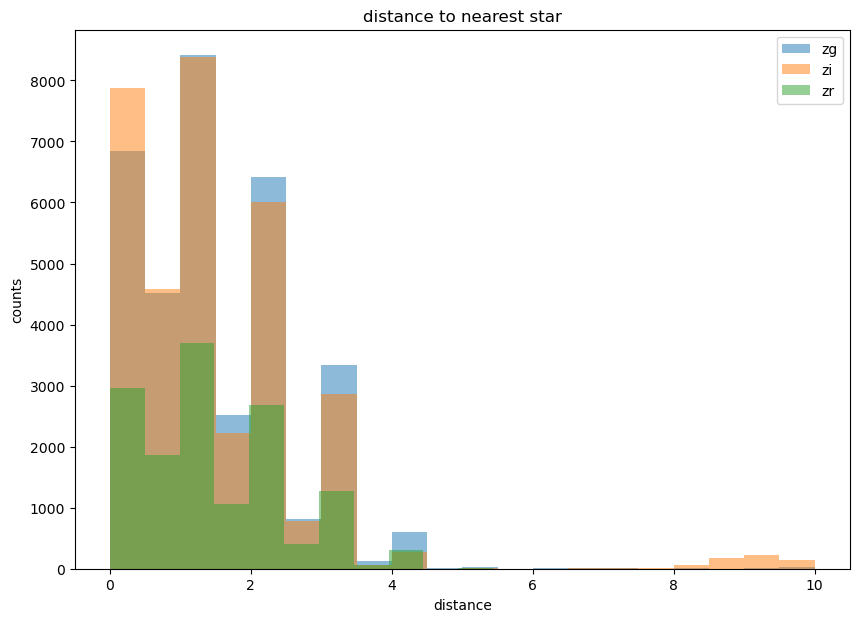

In [22]:
plt.hist(concat.loc[indices,'Diff'], bins=20, label='zg', alpha=.5)
plt.hist(concat.loc[indices2,'Diff'], bins=20, label='zi', alpha=.5)
plt.hist(concat.loc[indices3,'Diff'], bins=20, label='zr', alpha=.5)
plt.title('distance to nearest star')
plt.ylabel('counts')
plt.xlabel('distance')
plt.legend()

In [55]:
len(pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020297847_000449_zr_c07_x_0004._2_alllist_matched'))

0

In [108]:
plotlist_eff = ['Diff','brightness_ranking',
                'num_in_file_in_star',
                'detection_size','dist_to_implant',
                'A_from_implant',
                'sig_from_implant']

In [107]:
df_eff.iloc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020148032_000686_zg_c02_x_0001.
quad                                                          1
type                                                        pos
row_from_nn                                           38.714286
col_from_nn                                          240.071429
detection_size                                               42
closest_x                                                 250.0
closest_y                                                1761.0
Diff                                                  -0.071429
brightness_ranking                                            6
quadrant                                                      1
num_in_file_in_star                                        10.0
dup_indices                                                  []
is_smaller_dup                          

In [62]:
plotlist = ['sobel_ratio',
                                 'detection_size', 
            # 'log_snr',
            # 'log_detection_size',
                                 # 'Diff',
                                 # 'num_in_file',
                                 'num_in_file_in_star', 
                                 # 'sobel_norm_stdv_rat',
                                 # 'sobel_norm_diffmax',
                                 # 'max_num_consecutive_new',
                                ]

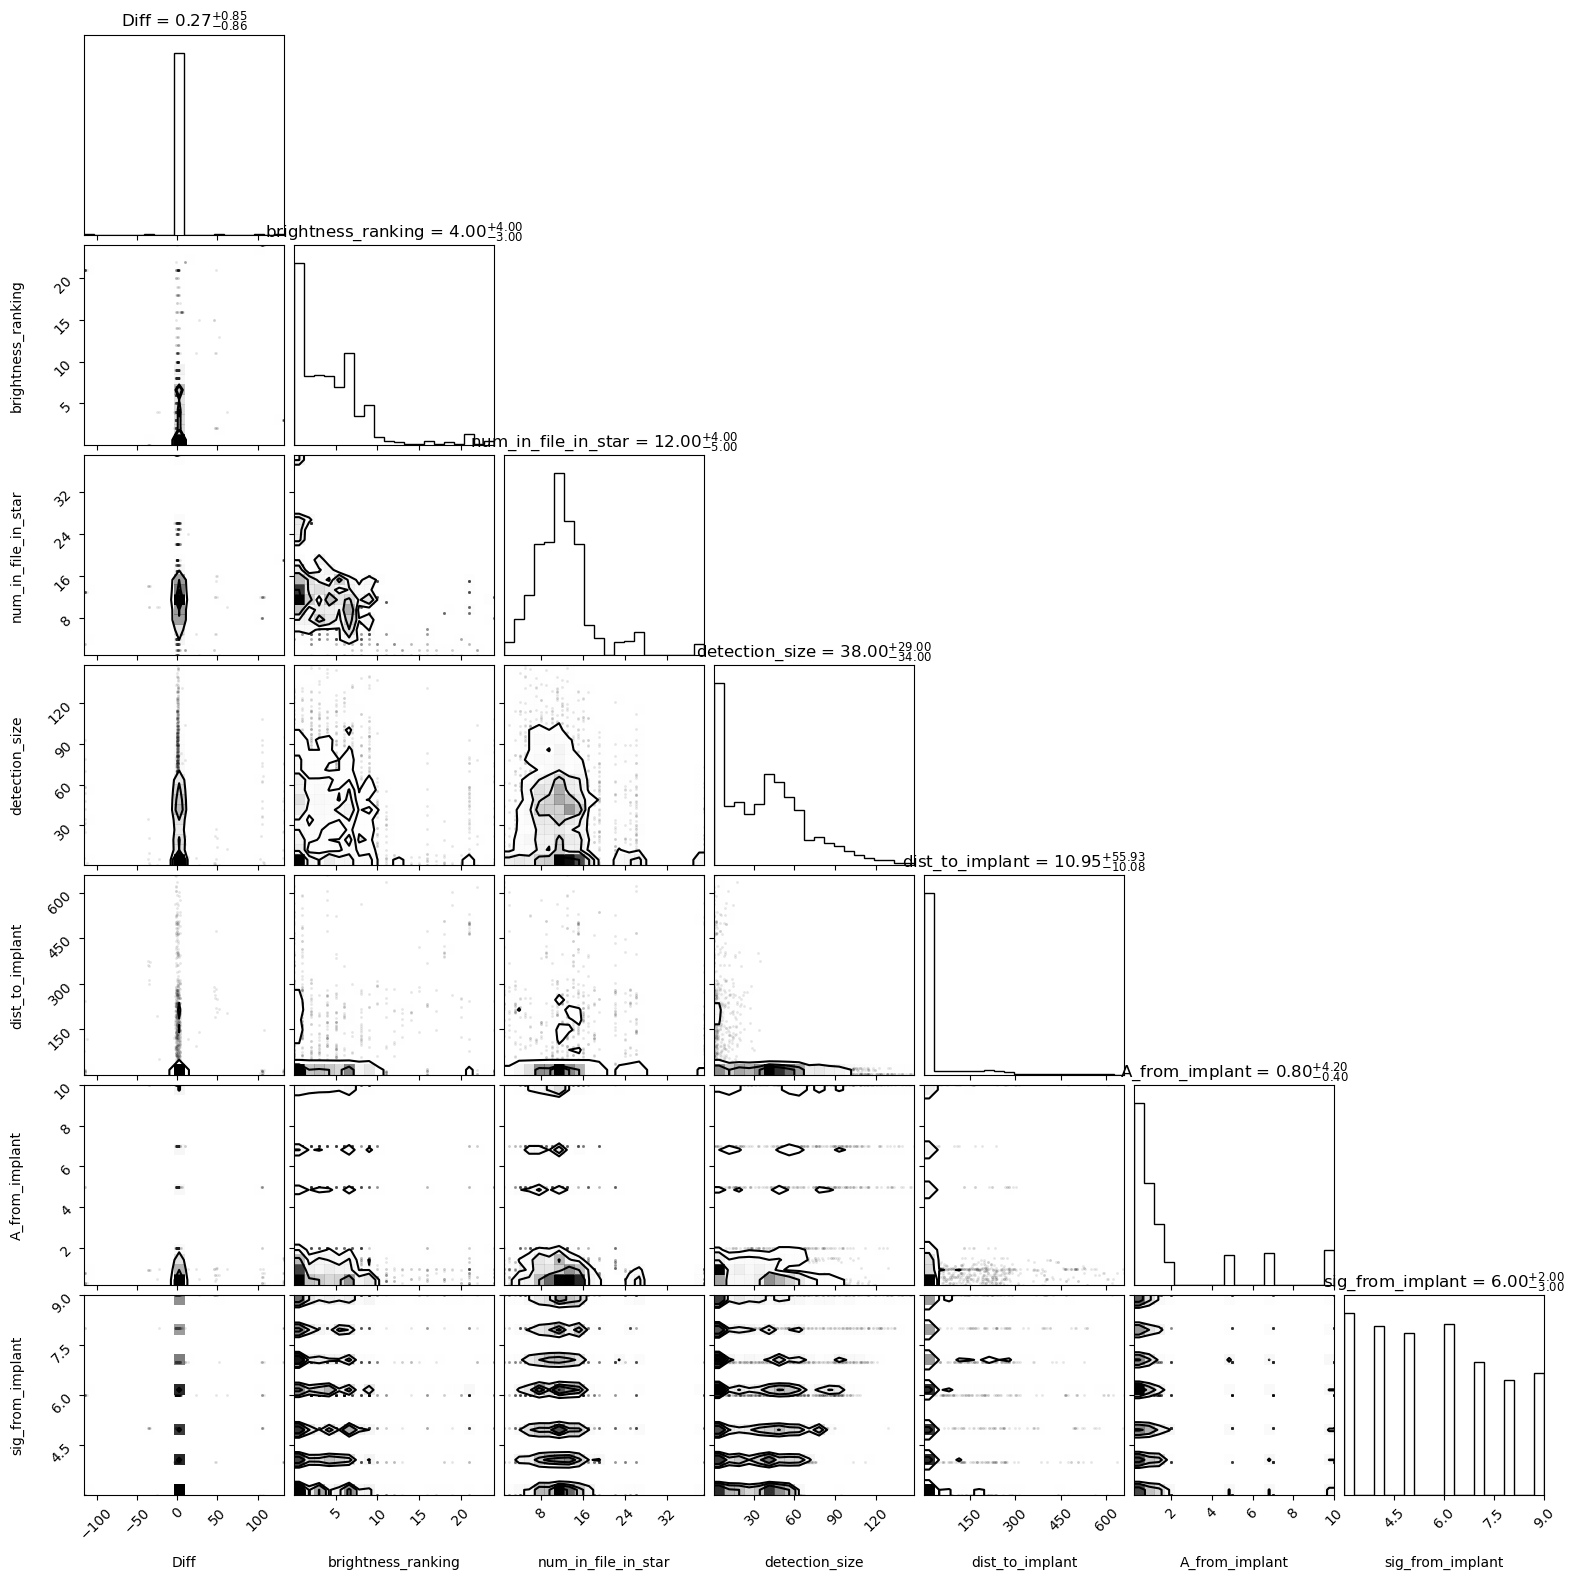

In [117]:
figure = corner.corner(df_eff[plotlist_eff],
                       labels=plotlist_eff,
    show_titles=True,
    title_kwargs={"fontsize": 12},)

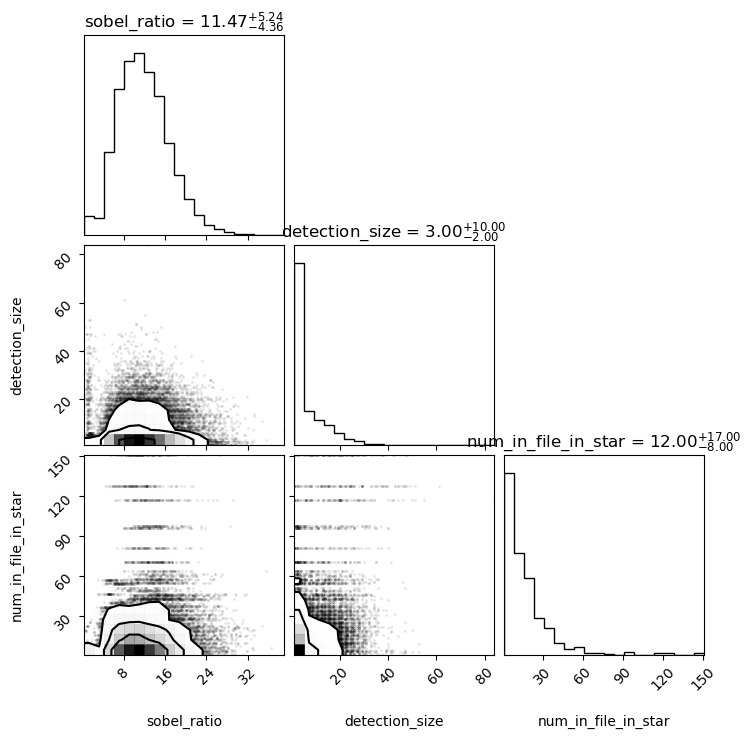

In [63]:
figure = corner.corner(concatsob[plotlist],
                       labels=plotlist,
    show_titles=True,
    title_kwargs={"fontsize": 12},)

In [63]:
thr='0.99'
test_name = 'average'
df_eff_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_"+test_name+"/df_matched_thr_"+thr)
df_eff_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_"+test_name+"/df_matched_thr_"+thr)

In [64]:
df_eff = pd.concat((df_eff_pos, df_eff_neg))

In [69]:
df_inf = concatsob

In [99]:
def rmdups(df, eff, size=False):
    if size==True:
        df.sort_values("detection_size", inplace=True)
        if eff==True:
            #removing "type",
            return df.drop_duplicates(subset=["filename", "row_from_implant", "col_from_implant"], keep="last")
        else:
            return df.drop_duplicates(subset=["filename", 
                                          "quad",
                                          "closest_x", "closest_y", "noise_local_new","height_new"], keep="last")
    if eff==True:
        df.sort_values("snr_local", inplace=True)
        # snr_local 
        #removing "type",
        return df.drop_duplicates(subset=["filename", "row_from_implant", "col_from_implant"], keep="last")
    else:
        df.sort_values("snr_local_new", inplace=True)
        return df.drdetsizelimduplicates(subset=["filename", 
                                          "quad",
                                          "closest_x", "closest_y", "noise_local_new","height_new"], keep="last")

In [127]:
def print_statement(smaller_eff,bigger_eff, smaller_inf, bigger_inf):
    print(f"The efficiency drops by {100*(len(bigger_eff)-len(smaller_eff))/len(bigger_eff):.1f} %.")
    bigger_eff_sig = bigger_eff[(bigger_eff['A_from_implant']>=1.1) | (bigger_eff['A_from_implant']<=.9)]
    smaller_eff_sig = smaller_eff[(smaller_eff['A_from_implant']>=1.1) | (smaller_eff['A_from_implant']<=.9)]

    print(f"For significant implants, the efficiency drops by {100*(len(bigger_eff_sig)-len(smaller_eff_sig))/len(bigger_eff_sig):.1f} %.")

    print(f"The number of candidates reduces by {100*(len(bigger_inf)-len(smaller_inf))/len(bigger_inf):.1f}% from {len(bigger_inf)} to {len(smaller_inf)}.")


In [125]:
#so if we do all the cuts...



def get_real_cands_print(df_inf, detsizelim=1, usesatflag=True, usesatneighbor=True, crstdvlim=3, diff=5, maxnuminstar=20,snr_thresh=1):
    
    df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_implants_pos")
    df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
    base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/"
    thr='0.99'
    test_name = 'average'
    df_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_"+test_name+"/df_matched_thr_"+thr)
    df_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_"+test_name+"/df_matched_thr_"+thr)
    # df_pos = pd.read_csv(base_path+"df_detections_pos_only")
    # df_neg = pd.read_csv(base_path+"df_detections_neg_only")
    both = pd.concat([df_neg,df_pos], ignore_index=True)
    both = rff.reduce_edges(both, 15)
    
    print(f"CNN efficiency: Found {len(rmdups(both, eff=True, size=True))} out of {len(df_implants_pos)+len(df_implants_neg)} transients, or {100*(len(rmdups(both, eff=True, size=True)))/(len(df_implants_pos)+len(df_implants_neg)):.1f}%")

    # matched = rff.match_stars_eff(both)
    matched = both[both["Diff"]<10]
    
    print(f"Matching to within {diff} of known stars (compared to within 10):")
    inf00 = df_inf[df_inf["Diff"]<diff]
    eff00 = rmdups(matched[np.abs(matched["Diff"])<diff], eff=True, size=True)
    # if 1==1:
    #     return eff00
    
    
    print_statement(eff00, rmdups(matched, eff=True, size=True), inf00, df_inf)    
    
    print(f"\n Restricting to stars with < {maxnuminstar} total candidates (just a guess):")
    inf0 = inf00[inf00["num_in_file_in_star"]<maxnuminstar]
    eff0 = eff00[eff00["num_in_file_in_star"]<maxnuminstar]
    
    
    print_statement(eff0, eff00, inf0, inf00)
    
    
#     print("\n Deduplication: ")
#     inf = inf0[inf0["is_smaller_dup"]==0]
#     eff = eff0[eff0["is_smaller_dup"]==0]
    
    
    # print_statement(eff, rmdups(eff0, eff=True), inf0, inf)
    
    print(f"\n Detection size > : {detsizelim}")
    inf2 = inf0[inf0['detection_size']>detsizelim]
    eff2 = eff0[eff0['detection_size']>detsizelim]
    
    
    print_statement(eff2, eff0, inf2, inf0)
    

#     print(f"\n Cosmic ray criterion with threshold: {crstdvlim}")
#     inf3 = inf2[inf2['sobel_norm_stdv_rat']>crstdvlim]
#     eff3 = eff2[eff2['sobel_norm_stdv_rat']>crstdvlim]
    
    
#     print_statement(eff3, eff2, inf3, inf2)
    
#     print("\nSatellite flag tbd should remove about 100 candidates")
    
#     print(f"\n After all this, if we look at transient candidates with snr > {snr_thresh}...")
    
#     inf4 = inf3[inf3['snr_local_new']>snr_thresh]
#     eff4 = eff3[eff3['snr_local']>snr_thresh] 
#     print_statement(eff4, eff3, inf4, inf3)
    

#     if maxnuminstar>0:
#         df = df[df['num_in_file_in_star']<maxnuminstar]
#     df = df[df['Diff']<=diff]
    # return df
                       #df = df[df[
    

In [132]:
get_real_cands_print(df_inf, detsizelim=1, usesatflag=False, usesatneighbor=False, crstdvlim=3, diff=5, maxnuminstar=30,snr_thresh=1)

Number of transient candidates reduced from 3004 to 3004.
CNN efficiency: Found 1051 out of 1600 transients, or 65.7%
Matching to within 5 of known stars (compared to within 10):
The efficiency drops by 1.0 %.
For significant implants, the efficiency drops by 0.9 %.
The number of candidates reduces by 1.6% from 31371 to 30862.

 Restricting to stars with < 30 total candidates (just a guess):
The efficiency drops by 0.7 %.
For significant implants, the efficiency drops by 0.5 %.
The number of candidates reduces by 13.9% from 30862 to 26574.

 Detection size > : 1
The efficiency drops by 1.8 %.
For significant implants, the efficiency drops by 1.1 %.
The number of candidates reduces by 30.7% from 26574 to 18408.


/tmp/ipykernel_8903/3716467948.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.sort_values("detection_size", inplace=True)


In [123]:
get_real_cands_print(df_inf, detsizelim=1, usesatflag=False, usesatneighbor=False, crstdvlim=3, diff=6, maxnuminstar=30,snr_thresh=1)

Number of transient candidates reduced from 3004 to 3004.
CNN efficiency: Found 1051 out of 1600 transients, or 65.7%
Matching to within 6 of known stars (compared to within 10):
The efficiency drops by 0.7 %.
The number of candidates reduces by 1.5% from 31371 to 30887.

 Restricting to stars with < 30 total candidates (just a guess):
The efficiency drops by 0.7 %.
The number of candidates reduces by 13.9% from 30887 to 26597.

 Detection size > : 1
The efficiency drops by 1.8 %.
The number of candidates reduces by 30.7% from 26597 to 18422.


/tmp/ipykernel_8903/3716467948.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.sort_values("detection_size", inplace=True)


In [98]:
len(df_eff[df_eff['Diff']<10])


2954

(array([1.600e+01, 0.000e+00, 0.000e+00, 8.000e+00, 2.928e+03, 7.000e+00,
        1.100e+01, 1.000e+00, 1.800e+01, 1.500e+01]),
 array([-115.51612903,  -90.68639113,  -65.85665323,  -41.02691532,
         -16.19717742,    8.63256048,   33.46229839,   58.29203629,
          83.12177419,  107.9515121 ,  132.78125   ]),
 <BarContainer object of 10 artists>)

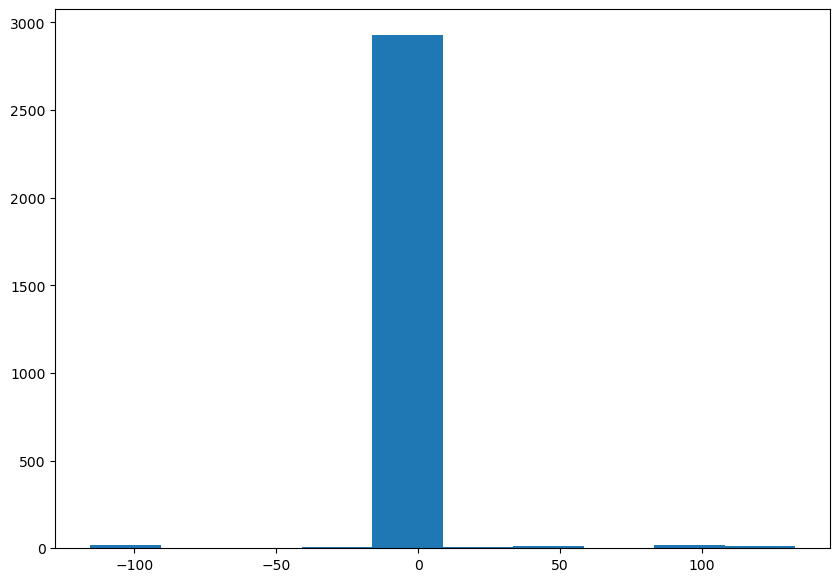

In [90]:
plt.hist(df_eff['Diff'])

In [143]:
def make_transient_detections_df(olddf, threshold=30):
    '''30 performs the best for thr=.99 
    lower than 30 decreases precision'''
    df = olddf.copy() #just to make sure i dont accidentally modify the old one in place
    newdf = pd.DataFrame()
    for filename, filenamegroup in df.groupby('filename'):  
        for quad, quadgroup in filenamegroup.groupby('quad'):
            for closest_x, closest_xgroup in quadgroup.groupby('closest_x'):
                ignore_in_this_group = []
                for i in closest_xgroup.index:
                    closest_idx = []
                    original_col = closest_xgroup.loc[i,'col_from_nn']
                    original_row = closest_xgroup.loc[i,'row_from_nn']
                    for j in closest_xgroup.index:
                        if j not in ignore_in_this_group:
                            if (np.abs(closest_xgroup.loc[j,'col_from_nn']-original_col)<5)*(np.abs(closest_xgroup.loc[j,'row_from_nn']-original_row)<threshold)*(j not in ignore_in_this_group):
                                # if (closest_xgroup.loc[j,'dist_to_implant']>20) or (closest_xgroup.loc[j,'A_from_implant']==closest_xgroup.loc[i,'A_from_implant']): 
                                #     #either matched to the same one or far away
                                    closest_idx.append(j)
                                    ignore_in_this_group.append(j)
                        # print(closest_idx)
                    if len(closest_idx)>0:
                        new_transient_y = np.average(closest_xgroup.loc[closest_idx, 'row_from_nn'])
                        new_transient_x = np.average(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        # print(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        # print(new_transient_x)
                        therow = closest_xgroup.loc[i].copy()
                        therow['row_from_nn']=new_transient_y
                        therow['col_from_nn']=new_transient_x
                        therow['type']='both'
                        # therow['dist_to_implant'] = np.sqrt((new_transient_x-closest_xgroup.loc[i, 'col_from_implant'])**2+(new_transient_y-closest_xgroup.loc[i, 'row_from_implant'])**2)
                        # print(therow)
                        newdf = pd.concat([newdf, therow.to_frame().T], ignore_index=True)
                    # newdf.append(therow, ignore_index=True)
                        # print(newdf)
                        # closest_xgroup.drop(index=closest_idx)
                        # print(len(closest_xgroup))
            # break
        # for idx in group.index:
    return newdf

In [135]:
matched = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020163819_000640_zg_c11_x_0014._4_alllist_matched')

In [144]:
newdf = make_transient_detections_df(matched)

In [145]:
newdf

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
0,14,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2046.25,134.25,4,144.0,2739.0,0.25
1,8,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,1319.727273,811.545455,11,821.0,101.0,0.545455
2,9,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,1610.925926,811.259259,27,821.0,101.0,0.259259
3,21,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2382.0,814.0,1,821.0,101.0,3.0
4,26,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2627.0,812.0,1,821.0,101.0,1.0
5,31,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,791.8,811.2,5,821.0,101.0,0.2
6,12,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,1908.5,1217.222222,18,1226.0,630.0,1.222222
7,25,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2575.0,1218.0,5,1226.0,630.0,2.0
8,22,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2398.0,1288.5,3,1296.0,1432.0,3.0
9,5,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,836.0,1359.0,5,1371.0,703.0,2.0


In [136]:
matched

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff
0,0,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,102.687500,1775.000000,16,1784.0,1857.0,1.000000
1,1,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,446.000000,2025.000000,3,2037.0,1520.0,2.000000
2,2,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,445.000000,2029.000000,1,2037.0,1520.0,2.000000
3,3,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,610.857143,2798.000000,14,2807.0,1809.0,1.000000
4,4,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,688.428571,2026.571429,7,2037.0,1520.0,0.428571
5,5,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,836.000000,1359.000000,5,1371.0,703.0,2.000000
6,6,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1009.000000,1359.000000,1,1371.0,703.0,2.000000
7,7,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1255.000000,2024.000000,1,2037.0,1520.0,3.000000
8,8,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1319.727273,811.545455,11,821.0,101.0,0.545455
9,9,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1610.925926,811.259259,27,821.0,101.0,0.259259


In [149]:
tot = rff.get_tot_csv(matched, 0) #len 3080

In [168]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [178]:
tot[0]

0       783.942017
1       752.374939
2       755.488525
3       729.818115
4       720.124817
           ...    
3075    749.611572
3076    770.228638
3077    740.941284
3078    755.059387
3079    786.092773
Name: flux_hap_2, Length: 3080, dtype: float64

In [179]:
row=120
np.argmax(tot[0][row - 10 : row + 10])

1

In [191]:
tot[3081]

IndexError: tuple index out of range

In [200]:
rff.get_snr_integrated(tot[0], 20)

(0.3620451351076333,
 0.3099815084585264,
 21.672418522638768,
 25.31245728545684,
 741.7677241920406,
 72.0741337181156,
 3,
 7.846393692137927)

In [151]:
row - 100 - newwid

-101

In [163]:
row = 3000
leftestleft, rightestleft, leftestright, rightestright = row - 100 - newwid,row - newwid, row + newwid,  row + 100 + newwid
bounds = np.array([leftestleft, rightestleft, leftestright, rightestright])
print(bounds)
for i, bound in enumerate(bounds):
    if bound < 0:
        bounds[i] = 0
    elif bound > 3079:
        bounds[i] = 3079
print(bounds)

[2889 2989 3011 3111]
[2889 2989 3011 3079]


In [162]:
bounds

array([  0,   0,  21, 121])

In [157]:
leftestleft, rightestleft, leftestright, rightestright 

(-101, -1, 21, 121)

In [150]:
row = 10
newwid = 11
np.concatenate((tot[ row - 100 - newwid : row - newwid], tot[row + newwid : row + 100 + newwid]))

ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 2 dimension(s) and the array at index 1 has 1 dimension(s)

In [237]:
def make_transient_detections_df(olddf, threshold=30):
    '''30 performs the best for thr=.99 
    lower than 30 decreases precision'''
    df = olddf.copy() #just to make sure i dont accidentally modify the old one in place
    newdf = pd.DataFrame()
    for filename, filenamegroup in df.groupby('filename'):  
        for quad, quadgroup in filenamegroup.groupby('quad'):
            for closest_x, closest_xgroup in quadgroup.groupby('closest_x'):
                ignore_in_this_group = []
                for i in closest_xgroup.index:
                    closest_idx = []
                    original_col = closest_xgroup.loc[i,'col_from_nn']
                    original_row = closest_xgroup.loc[i,'row_from_nn']
                    for j in closest_xgroup.index:
                        if j not in ignore_in_this_group:
                            if (np.abs(closest_xgroup.loc[j,'col_from_nn']-original_col)<5)*(np.abs(closest_xgroup.loc[j,'row_from_nn']-original_row)<threshold)*(j not in ignore_in_this_group):
                                # if (closest_xgroup.loc[j,'dist_to_implant']>20) or (closest_xgroup.loc[j,'A_from_implant']==closest_xgroup.loc[i,'A_from_implant']): 
                                #     #either matched to the same one or far away
                                    closest_idx.append(j)
                                    ignore_in_this_group.append(j)
                        # print(closest_idx)
                    if len(closest_idx)>0:
                        new_transient_y = np.average(closest_xgroup.loc[closest_idx, 'row_from_nn'])
                        original_rows = np.array(closest_xgroup.loc[closest_idx, 'row_from_nn'])
                        new_transient_x = np.average(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        original_cols = np.array(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        # print(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        # print(new_transient_x)
                        therow = closest_xgroup.loc[i].copy()
                        detection_sizes = np.array(closest_xgroup.loc[closest_idx, 'detection_size'])
                        therow['row_from_nn']=new_transient_y
                        therow['col_from_nn']=new_transient_x
                        therow['original_cols']=original_cols
                        therow['original_rows']=original_rows
                        therow['detection_size']=np.sum(closest_xgroup.loc[closest_idx, 'detection_size'])
                        
                        detection_sizes = np.array(closest_xgroup.loc[closest_idx, 'detection_size'])
                        therow['detection_sizes']=detection_sizes
                        if len(closest_idx)>1:
                            modified_flag=True
                            therow['type']='both'
                        else:
                            modified_flag=False
                        therow['modified_flag'] = modified_flag
                        # therow['dist_to_implant'] = np.sqrt((new_transient_x-closest_xgroup.loc[i, 'col_from_implant'])**2+(new_transient_y-closest_xgroup.loc[i, 'row_from_implant'])**2)
                        # print(therow)
                        newdf = pd.concat([newdf, therow.to_frame().T], ignore_index=True)
                    # newdf.append(therow, ignore_index=True)
                        # print(newdf)
                        # closest_xgroup.drop(index=closest_idx)
                        # print(len(closest_xgroup))
            # break
        # for idx in group.index:
    return newdf

In [48]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [49]:
newdf = rff.make_aggregated_transient_detections_df(matched)

In [149]:
newdf

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,original_cols,original_rows,detection_sizes,modified_flag
0,14,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,2046.25,134.25,4,144.0,2739.0,0.25,[134.25],[2046.25],[4],False
1,8,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1319.727273,811.545455,11,821.0,101.0,0.545455,[811.5454545454545],[1319.7272727272727],[11],False
2,9,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1610.925926,811.259259,27,821.0,101.0,0.259259,[811.2592592592592],[1610.925925925926],[27],False
3,21,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,2382.0,814.0,1,821.0,101.0,3.0,[814.0],[2382.0],[1],False
4,26,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2627.0,812.0,3,821.0,101.0,1.0,"[810.0, 812.0, 814.0]","[2627.0, 2627.0, 2627.0]","[1, 1, 1]",True
5,31,ztf_20221020163819_000640_zg_c11_x_0014.,4,neg,791.8,811.2,5,821.0,101.0,0.2,[811.2],[791.8],[5],False
6,12,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1908.5,1217.222222,18,1226.0,630.0,1.222222,[1217.2222222222222],[1908.5],[18],False
7,25,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,2575.0,1218.0,5,1226.0,630.0,2.0,[1218.0],[2575.0],[5],False
8,22,ztf_20221020163819_000640_zg_c11_x_0014.,4,both,2398.0,1288.5,4,1296.0,1432.0,3.0,"[1289.0, 1288.0]","[2394.0, 2402.0]","[3, 1]",True
9,5,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,836.0,1359.0,5,1371.0,703.0,2.0,[1359.0],[836.0],[5],False


In [51]:
newtot, maxcol = rff.get_tot_csv(newdf, 24)

In [232]:
newdf = add_snr_both(matched)

0


In [233]:
newdf

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,snr_local_new,snr_global_new,noise_local_new,noise_global_new,local_average_outside_new,height_new,FWHM_new,signal_local_new
0,0,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,102.687500,1775.000000,16,1784.0,1857.0,1.000000,0.590111,0.514480,22.055657,25.297916,744.227794,60.614125,5.0,13.015278
1,1,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,446.000000,2025.000000,3,2037.0,1520.0,2.000000,0.665287,0.625555,26.348043,28.021563,850.183393,66.516192,8.0,17.529020
2,2,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,445.000000,2029.000000,1,2037.0,1520.0,2.000000,0.665287,0.625555,26.348043,28.021563,850.183393,66.516192,8.0,17.529020
3,3,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,610.857143,2798.000000,14,2807.0,1809.0,1.000000,0.733781,0.725751,17.729268,17.925427,477.724500,46.644091,6.0,13.009398
4,4,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,688.428571,2026.571429,7,2037.0,1520.0,0.428571,0.471702,0.542514,31.627785,27.499571,845.234220,68.389986,5.0,14.918896
5,5,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,836.000000,1359.000000,5,1371.0,703.0,2.000000,0.400722,0.456836,34.310544,30.096131,899.070292,81.247091,4.0,13.749002
6,6,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1009.000000,1359.000000,1,1371.0,703.0,2.000000,0.225553,0.258122,34.386361,30.047496,899.552721,90.716051,2.0,7.755934
7,7,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1255.000000,2024.000000,1,2037.0,1520.0,3.000000,0.485902,0.492862,28.368495,27.967855,864.677357,42.159313,7.0,13.784294
8,8,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1319.727273,811.545455,11,821.0,101.0,0.545455,0.311436,0.315751,24.831891,24.492556,696.418678,65.299659,3.0,7.733540
9,9,ztf_20221020163819_000640_zg_c11_x_0014.,4,pos,1610.925926,811.259259,27,821.0,101.0,0.259259,0.809298,0.724185,22.075451,24.669967,697.622232,71.745688,7.0,17.865608


In [225]:
rff.get_tot_csv?

Signature:
rff.get_tot_csv(
    df,
    index,
    lc_filename=None,
    half_aperture=2,
    lcfpath='/lustre/lrspec/ZTF_data/lightcurves/1020/',
)
Docstring:
returns tot, maxcols: an array that is the flux of the star streak
given an aperture that is halfaperture*2+1
and if tracking=true, tracks when the streak posittion fluctuates
oif tracking==false, goes based on average center of streak
put in lc_filename yourself or it will take it from the dataframe 
(in which case df and index are ignored)
File:      ~/rwe/review_findings_functions.py
Type:      function

In [27]:
# tot, maxcol = rff.get_tot_csv(matched, 12)

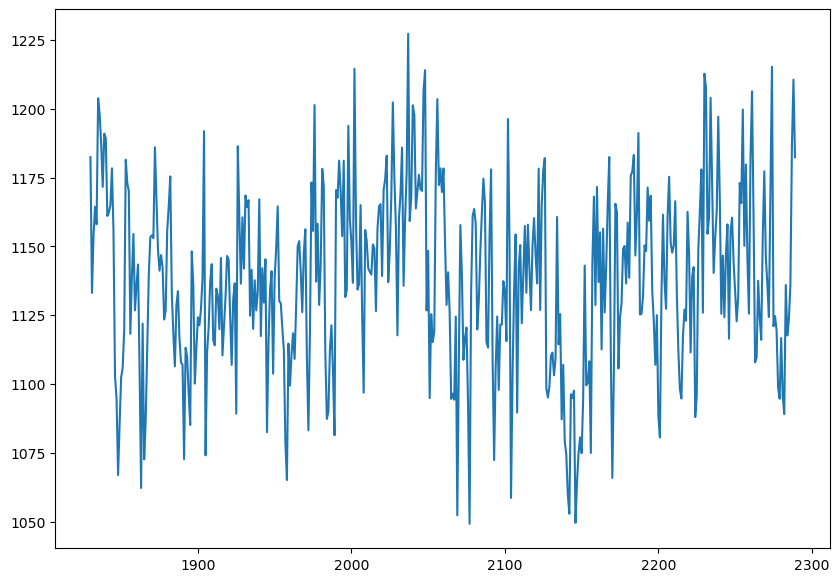

In [60]:
plt.plot(newtot[2030-200:2090+200])

In [243]:
np.array(newdf.loc[0, 'original_rows'])

array([2046.25])

In [80]:
get_snr_brightest(newtot, [[2049.5, 2072.0, 2075.5]])

indices for size of integral:  1 1
81.77602050781252
40.88801025390626
1132.318583984375
2047    74.376851
2048    81.776021
2049    -5.577007
Name: flux_hap_2, dtype: float64


(0.36170149536069107,
 0.36777985336675884,
 33.925587564708174,
 33.36489381028749,
 1132.318583984375,
 81.77602050781252,
 3,
 12.270935753145013,
 2048)

In [58]:
get_snr_dimmest(newtot, [[2049.5, 2072.0, 2075.5]])

indices for size of integral:  1 1
-89.87240112304698
-44.93620056152349
1139.061121826172
2076   -46.123011
2077   -89.872401
Name: flux_hap_2, dtype: float64


(0.3326181394476238,
 0.34994586716667514,
 35.060346149929316,
 33.32431726997597,
 1139.061121826172,
 -89.87240112304698,
 2,
 11.661707104779149,
 2077)

In [62]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [70]:
tot_eff, maxcols = rff.get_tot_npy(df_eff_pos, 0, 'pos')

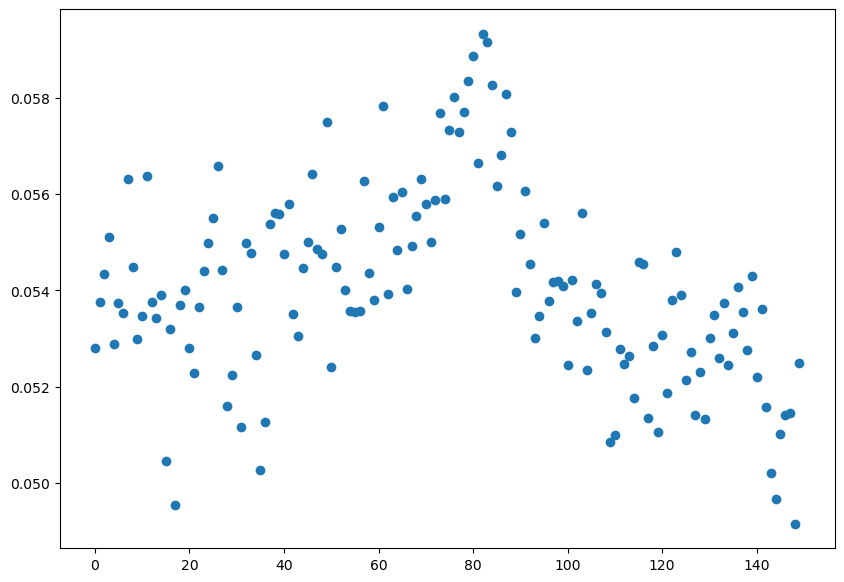

In [104]:
x = tot_eff[1750:1900]
plt.scatter(np.arange(0, len(x)), x)

In [142]:
get_snr_brightest(tot_eff, [1830])

indices for size of integral:  7 3
0.005670532751828432
0.002835266375914216
0.05365999771282077
[0.00367979 0.00435986 0.00362779 0.00404699 0.00469021 0.00519868
 0.0029953  0.00567053 0.00549471 0.00460282]


(131.93328413260593,
 5.196590772275814,
 0.0015965189014910638,
 0.04053310931798669,
 0.05365999771282077,
 0.005670532751828432,
 10,
 0.21063398185349644,
 1832)

In [143]:
get_snr_dimmest(tot_eff, [1830])

indices for size of integral:  0 1
0.00027661217376589997
0.00013830608688294999
0.05368510069325566
[0.00027661]


(-10.244384198738752,
 -0.4103298699158411,
 0.0016234906328589248,
 0.04053241795307641,
 0.05368510069325566,
 0.00027661217376589997,
 1,
 -0.016631661786060344,
 1839)

In [125]:
totneg, maxcol = rff.get_tot_npy(df_eff_neg, 0, 'neg')

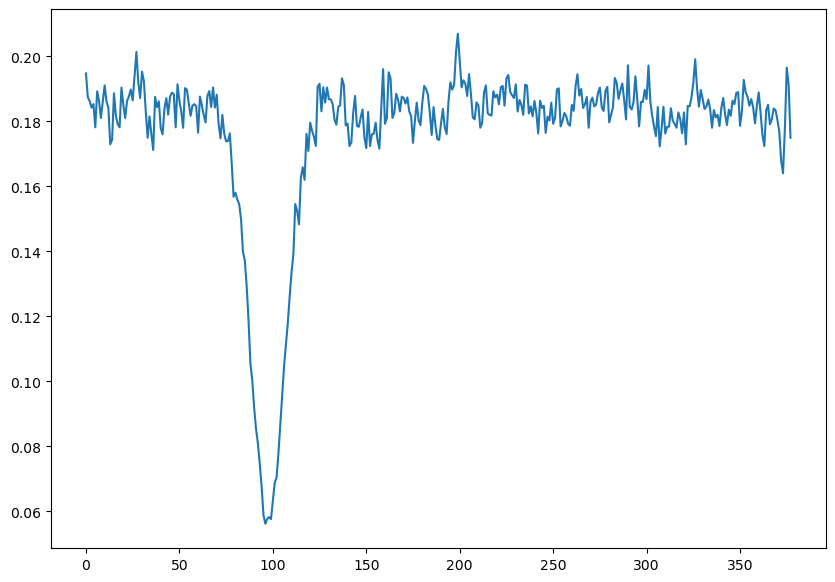

In [136]:
plt.plot(totneg[:378])

In [144]:
get_snr_dimmest(totneg, [87.225, 110.5, 98.97872340425532] 	)

indices for size of integral:  9 13
-0.12941551834344864
-0.06470775917172432
0.18559754520654678
[-0.06695177 -0.0801147  -0.0852876  -0.09363308 -0.10014414 -0.10470308
 -0.11091152 -0.11795886 -0.12676128 -0.12941552 -0.12792964 -0.12735382
 -0.12798978 -0.12259418 -0.11687612 -0.11514559 -0.10772778 -0.09907225
 -0.08996876 -0.08093107 -0.07448506 -0.06772501]


(319.78175210193126,
 132.98628936901505,
 0.004715318680255541,
 0.011338558857800628,
 0.18559754520654678,
 -0.12941551834344864,
 22,
 1.507872869291083,
 96)

In [145]:
get_snr_brightest(totneg, [87.225, 110.5, 98.97872340425532] 	)

indices for size of integral:  0 1
-0.0095873686671257
-0.00479368433356285
0.18591412037611008
[-0.00958737]


(-17.307545438800172,
 -8.639771088669697,
 0.005657365444437976,
 0.01133306756493992,
 0.18591412037611008,
 -0.0095873686671257,
 1,
 -0.0979151094935082,
 77)

In [128]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [129]:
rff.make_aggregated_transient_detections_df(df_eff_neg)

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,original_cols,original_rows,detection_sizes,modified_flag,original_types
0,1639,1639,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,98.901241,84.812823,149,95.0,100.0,...,11.775106,109.0,95.0,0.3,6.0,"[85.05, 84.51612903225806, 84.87234042553192]","[87.225, 110.5, 98.97872340425532]","[40, 62, 47]",True,"[pos, pos, neg]"
1,1651,1651,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,649.22416,84.654337,113,95.0,100.0,...,10.141362,659.0,94.0,0.6,5.0,"[85.08333333333333, 84.3913043478261, 84.48837...","[638.9166666666666, 659.5, 649.2558139534884]","[24, 46, 43]",True,"[pos, pos, neg]"
2,1656,1656,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,1175.798878,84.181891,55,95.0,100.0,...,17.815241,1195.0,94.0,0.5,7.0,"[84.3125, 84.05128205128206]","[1167.1875, 1184.4102564102564]","[16, 39]",True,"[pos, neg]"
3,1657,1657,ztf_20221020138241_000686_zi_c05_x_0000.,1,pos,1198.4,83.984615,65,95.0,100.0,...,13.400009,1195.0,94.0,0.5,7.0,[83.98461538461538],[1198.4],[65],False,[pos]
4,1672,1672,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,1782.227283,83.750592,143,95.0,100.0,...,10.898914,1792.0,94.0,0.5,5.0,"[83.82051282051282, 83.54237288135593, 83.8888...","[1771.1025641025642, 1793.4237288135594, 1782....","[39, 59, 45]",True,"[pos, pos, neg]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
862,185,185,ztf_20221020294271_000449_zr_c04_x_0004.,4,pos,1828.333333,2906.333333,6,2917.0,801.0,...,9.689628,1848.0,2917.0,0.99,6.0,[2906.333333333333],[1828.3333333333333],[6],False,[pos]
863,195,195,ztf_20221020294271_000449_zr_c04_x_0004.,4,pos,2013.0,2904.0,1,2917.0,801.0,...,175.025712,1848.0,2917.0,0.99,6.0,[2904.0],[2013.0],[1],False,[pos]
864,201,201,ztf_20221020294271_000449_zr_c04_x_0004.,4,both,2353.035714,2907.29803,86,2917.0,801.0,...,15.431217,2371.0,2917.0,0.5,9.0,"[2907.285714285714, 2907.310344827586]","[2345.5714285714284, 2360.5]","[28, 58]",True,"[pos, neg]"
865,203,203,ztf_20221020294271_000449_zr_c04_x_0004.,4,pos,2376.25,2906.592105,76,2917.0,801.0,...,15.255454,2371.0,2917.0,0.5,9.0,[2906.592105263158],[2376.25],[76],False,[pos]


In [147]:
df_eff_neg.iloc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020154120_000640_zi_c03_x_0002.
quad                                                          4
type                                                        pos
row_from_nn                                           73.642857
col_from_nn                                          542.857143
detection_size                                               28
closest_x                                                 553.0
closest_y                                                1495.0
Diff                                                   0.142857
brightness_ranking                                            3
quadrant                                                      4
num_in_file_in_star                                        15.0
dup_indices                                                  []
is_smaller_dup                          

In [151]:
def add_snr_both(olddf):
    '''
    add pos and neg integrated snrs
    returns the dataframe with new columns for outputs of
    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, brightest/dimmest row 
    currently hardcoded half ap = 2
    '''
    wid=10
    df = olddf.copy()
    column_names_brightening = ['snr_local_brightening', 'snr_global_brightening', 'noise_local_brightening', 'noise_global_brightening', 
                'local_average_outside_brightening', 'height_brightening', 'FWHM_brightening', 'signal_local_brightening', 'central_point_brightening']
    column_names_dimming = ['snr_local_dimming', 'snr_global_dimming', 'noise_local_dimming', 'noise_global_dimming', 
                'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming', 'signal_local_dimming', 'central_point_dimming']

    for col in column_names_brightening:
        df[col] = np.zeros(len(df))
    for col in column_names_dimming:
        df[col] = np.zeros(len(df))
    for filename, filenamegroup in df.groupby('filename'):  
        for quad, quadgroup in filenamegroup.groupby('quad'):
            for closest_x, closest_xgroup in quadgroup.groupby('closest_x'): #which light curve it is
                tot, maxcols = rff.get_tot_csv(df, closest_xgroup.index[0]) #will be the same for all so just using the first
                for index in closest_xgroup.index:
                    row = int(df.loc[index, "row_from_nn"]) + wid
                    aggrows = df.loc[index, "original_rows"]
                    #first brightening
                    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute = get_snr_brightest(tot, aggrows)                    
                    df.loc[index, column_names_brightening] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute]
                    #now dimming
                    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute = get_snr_dimmest(tot, aggrows)                    
                    df.loc[index, column_names_dimming] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute]
    return df            



In [168]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [169]:
snrtest = add_snr_both(newdf)

(array([10.,  7.,  3.,  3.,  0.,  1.,  1.,  0.,  0.,  1.]),
 array([1. , 1.8, 2.6, 3.4, 4.2, 5. , 5.8, 6.6, 7.4, 8.2, 9. ]),
 <BarContainer object of 10 artists>)

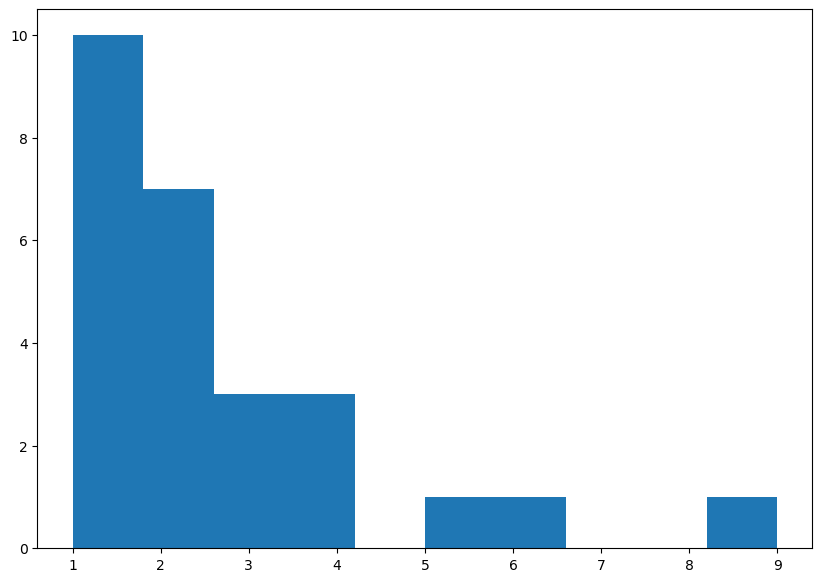

In [170]:
plt.hist(snrtest['FWHM_brightening'])

(array([1., 0., 1., 1., 3., 4., 7., 4., 3., 2.]),
 array([-0.75087564, -0.62634646, -0.50181728, -0.3772881 , -0.25275892,
        -0.12822974, -0.00370056,  0.12082862,  0.2453578 ,  0.36988698,
         0.49441616]),
 <BarContainer object of 10 artists>)

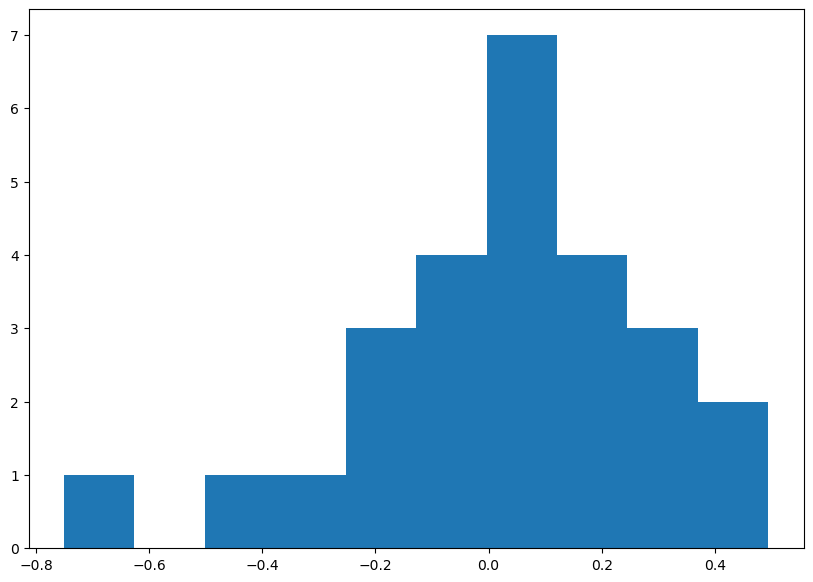

In [164]:
plt.hist(snrtest['snr_local_dimming']-snrtest['snr_local_brightening'])

(array([11.,  8.,  0.,  0.,  1.,  2.,  3.,  0.,  0.,  1.]),
 array([-0.5       ,  2.31666667,  5.13333333,  7.95      , 10.76666667,
        13.58333333, 16.4       , 19.21666667, 22.03333333, 24.85      ,
        27.66666667]),
 <BarContainer object of 10 artists>)

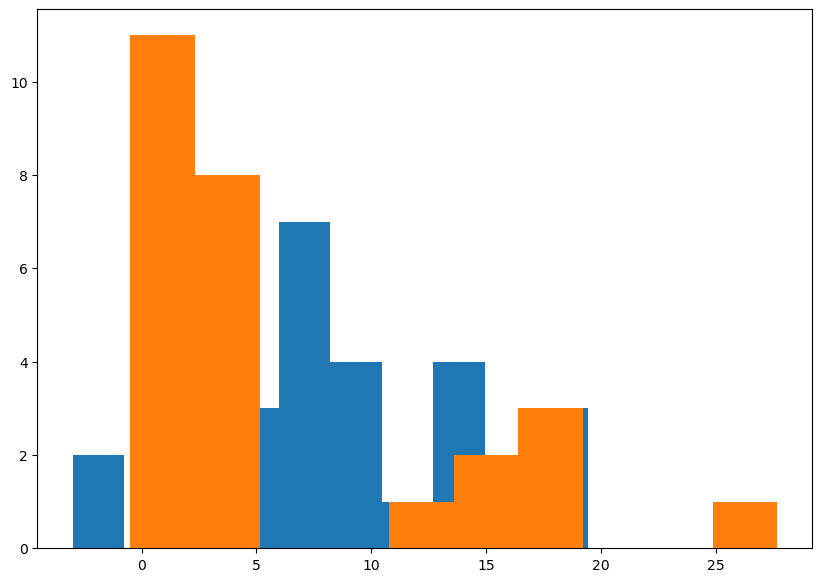

In [156]:
plt.hist(snrtest['row_from_nn']+10-snrtest['central_point_dimming'], label='dimming')
plt.hist(snrtest['row_from_nn']+10-snrtest['central_point_brightening'], label='brightening')

In [183]:
matched = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020297847_000449_zr_c05_x_0014._3_alllist_matched')

In [199]:
agg = rff.make_aggregated_transient_detections_df(matched)

In [197]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [200]:
rff.add_snr_both(agg)

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,...,central_point_brightening,snr_local_dimming,snr_global_dimming,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming
0,0,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,16.464286,1330.678571,26,1340.0,204.0,0.5,...,39.0,0.195235,0.160935,172.641370,209.435431,6364.081001,-622.294868,2.0,33.705575,20.0
1,1,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,39.913043,1330.793478,41,1340.0,204.0,0.857143,...,39.0,0.154928,0.120220,162.692239,209.662616,6366.309478,-242.800200,3.0,25.205536,45.0
2,2,ztf_20221020297847_000449_zr_c05_x_0014.,3,pos,73.166667,1330.666667,6,1340.0,204.0,1.086957,...,76.0,0.190023,0.160394,177.552656,210.351445,6316.109131,-373.608643,4.0,33.739177,81.0
3,3,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,460.339161,1331.400932,26,1340.0,204.0,3.0,...,482.0,0.222329,0.190276,179.836822,210.131147,6342.937415,-406.690833,5.0,39.982981,469.0
4,7,ztf_20221020297847_000449_zr_c05_x_0014.,3,pos,584.764706,1331.117647,17,1340.0,204.0,1.117647,...,596.0,0.135605,0.179511,278.567511,210.433548,6285.875947,-349.342744,5.0,37.775225,585.0
5,10,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,671.535714,1330.071429,15,1340.0,204.0,1.142857,...,673.0,0.099559,0.103236,210.241917,202.753934,6344.841233,-283.081956,2.0,20.931467,666.0
6,13,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,961.0,1331.125,6,1340.0,204.0,2.75,...,972.0,0.062958,0.059300,200.283871,212.635657,6309.878442,-158.996606,1.0,12.609386,961.0
7,15,ztf_20221020297847_000449_zr_c05_x_0014.,3,pos,1040.181818,1330.909091,11,1340.0,204.0,0.909091,...,1052.0,0.195668,0.152698,164.908293,211.314475,6347.650090,-305.136418,4.0,32.267313,1043.0
8,17,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,1144.875,1331.0,27,1340.0,204.0,1.0,...,1161.0,0.211320,0.202014,201.700990,210.992471,6318.848987,-466.046741,5.0,42.623383,1151.0
9,18,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,1191.3,1330.1,30,1340.0,204.0,1.0,...,1198.0,0.277369,0.240695,181.920019,209.638204,6310.070232,-384.873943,9.0,50.458970,1208.0


In [186]:
agg

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,original_cols,original_rows,detection_sizes,modified_flag,original_types
0,0,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,16.464286,1330.678571,26,1340.0,204.0,0.5,"[1330.5, 1330.857142857143]","[5.0, 27.928571428571427]","[12, 14]",True,"[pos, pos]"
1,1,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,39.913043,1330.793478,41,1340.0,204.0,0.857143,"[1331.0869565217392, 1330.5]","[43.82608695652174, 36.0]","[23, 18]",True,"[pos, neg]"
2,2,ztf_20221020297847_000449_zr_c05_x_0014.,3,pos,73.166667,1330.666667,6,1340.0,204.0,1.086957,[1330.6666666666667],[73.16666666666667],[6],False,[neg]
3,3,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,460.339161,1331.400932,26,1340.0,204.0,3.0,"[1333.0, 1330.3846153846157, 1330.8181818181818]","[451.5, 470.1538461538461, 459.3636363636364]","[2, 13, 11]",True,"[pos, pos, neg]"
4,7,ztf_20221020297847_000449_zr_c05_x_0014.,3,pos,584.764706,1331.117647,17,1340.0,204.0,1.117647,[1331.1176470588234],[584.7647058823529],[17],False,[pos]
5,10,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,671.535714,1330.071429,15,1340.0,204.0,1.142857,"[1331.142857142857, 1329.0]","[664.0714285714286, 679.0]","[14, 1]",True,"[pos, pos]"
6,13,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,961.0,1331.125,6,1340.0,204.0,2.75,"[1332.75, 1329.5]","[961.0, 961.0]","[4, 2]",True,"[pos, pos]"
7,15,ztf_20221020297847_000449_zr_c05_x_0014.,3,pos,1040.181818,1330.909091,11,1340.0,204.0,0.909091,[1330.909090909091],[1040.1818181818182],[11],False,[pos]
8,17,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,1144.875,1331.0,27,1340.0,204.0,1.0,"[1331.0, 1331.0]","[1148.75, 1141.0]","[12, 15]",True,"[pos, neg]"
9,18,ztf_20221020297847_000449_zr_c05_x_0014.,3,both,1191.3,1330.1,30,1340.0,204.0,1.0,"[1331.0, 1329.2]","[1187.0, 1195.6]","[25, 5]",True,"[pos, neg]"


In [203]:
concat2 = pd.read_csv("/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat")

In [5]:
concat1

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,sobel_ratio,sobels_x,sobels_y,quadrant,num_in_file_in_star
0,0,0,0,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,34.000000,1752.000000,15,1760.0,1586.0,2.000000,15.335986,[[-1.88607025e+01 2.60816956e+00 1.07009277e...,[[-6.60966492e+00 -1.33075104e+01 -2.56719971e...,4,9.0
1,1,1,1,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,43.960000,186.600000,25,195.0,1398.0,1.600000,12.280559,[[ 9.504593 18.13031 21.489899 -...,[[ 1.06905670e+01 9.85134888e+00 3.16265869e...,4,1.0
2,2,2,2,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,140.875000,2482.000000,8,2492.0,1589.0,0.000000,10.913323,[[-1.14753723e+00 -4.11605835e-01 3.91306458e...,[[-1.15688629e+01 -8.30720520e+00 -1.83418274e...,4,38.0
3,3,3,3,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,177.500000,2481.875000,8,2492.0,1589.0,0.125000,23.278704,[[ 2.59413452e+01 2.05364075e+01 -1.61590118e...,[[ 1.64836426e+01 -6.06045532e+00 -1.79442291e...,4,38.0
4,4,4,4,ztf_20221020163819_000640_zg_c13_x_0004.,4,pos,223.714286,2482.928571,14,2492.0,1589.0,0.928571,17.015619,[[-2.02168274e+00 -4.99195862e+00 7.45707703e...,[[-1.44947815e+00 -5.83714294e+00 9.43461609e...,4,38.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81750,81750,66,66,ztf_20221020154120_000640_zi_c13_x_0017.,4,neg,2017.000000,1490.000000,1,1502.0,840.0,2.000000,9.248420,[[ 2.47772369e+01 1.49582214e+01 -1.45050354e...,[[ 3.05165100e+00 -9.19372559e-01 1.06620483e...,4,10.0
81751,81751,67,67,ztf_20221020154120_000640_zi_c13_x_0017.,4,neg,2017.000000,1492.000000,1,1502.0,840.0,0.000000,7.867667,[[-4.68601990e+00 2.19771729e+01 1.55041656e...,[[ 1.74752960e+01 1.18697205e+01 1.49516296e...,4,10.0
81752,81752,68,68,ztf_20221020154120_000640_zi_c13_x_0017.,4,neg,2245.625000,968.750000,8,978.0,2007.0,0.750000,18.779884,[[-6.58267212e+00 -7.22468567e+00 -3.49984741e...,[[-32.362335 -16.09169 6.000183 12.6...,4,12.0
81753,81753,69,69,ztf_20221020154120_000640_zi_c13_x_0017.,4,neg,2964.000000,1492.000000,1,1502.0,840.0,0.000000,9.868550,[[-1.03326569e+01 3.52775574e+01 1.25991821e...,[[ 7.62712097e+00 -8.85253906e-01 -1.57162170e...,4,10.0


In [202]:
concat2.loc[0]

NameError: name 'concat2' is not defined

In [217]:
brightening = concat2[concat2['snr_local_brightening']>3]

In [20]:
len(brightening)

25

In [17]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [25]:
brightening

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,snr_global_dimming,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star
1242,1242,5,12,ztf_20221020157697_000640_zi_c05_x_0000.,1,both,1558.134409,1897.122312,62,1906.0,...,0.603099,12.360876,12.441343,160.898010,-22.429825,3.0,7.503358,1562.0,1,1.0
2313,2313,19,27,ztf_20221020154120_000640_zi_c10_x_0014.,4,both,2920.379960,1831.054563,77,1841.0,...,0.410498,15.599457,15.594136,300.446024,-40.977426,1.0,6.401361,2942.0,4,1.0
6800,6800,0,0,ztf_20221020294271_000449_zr_c08_x_0000.,2,pos,2100.000000,2042.000000,3,2052.0,...,-0.457004,10.914363,10.346761,135.532584,22.358820,1.0,-4.728511,2102.0,2,1.0
8429,8429,18,0,ztf_20221020297847_000449_zr_c13_x_0016.,2,both,558.657143,1069.421429,80,1079.0,...,0.295680,16.537170,17.149899,334.193604,-25.713807,1.0,5.070878,555.0,2,1.0
9811,9811,2,43,ztf_20221020294271_000449_zr_c03_x_0010.,4,neg,686.750000,707.250000,4,715.0,...,0.403475,9.116295,9.480324,78.413629,-14.631220,1.0,3.825078,702.0,4,1.0
11290,11290,0,3,ztf_20221020294271_000449_zr_c15_x_0016.,1,both,1959.309524,468.940476,49,477.0,...,0.487351,9.821957,9.896485,82.958788,-23.261919,1.0,4.823061,1959.0,1,1.0
11780,11780,6,13,ztf_20221020141806_000686_zi_c09_x_0006.,2,both,2933.200000,2254.533333,9,2263.0,...,0.324203,29.052301,28.709790,966.311865,-55.648229,2.0,9.307803,2923.0,2,1.0
14357,14357,19,30,ztf_20221020138241_000686_zi_c14_x_0028.,4,pos,734.500000,2580.000000,4,2592.0,...,-0.607790,15.965442,23.285462,386.439760,200.297972,1.0,-14.152667,734.0,4,2.0
14358,14358,20,32,ztf_20221020138241_000686_zi_c14_x_0028.,4,both,762.350000,2585.600000,13,2592.0,...,0.217855,22.366467,23.706374,397.670368,-16.346576,2.0,5.164548,785.0,4,2.0
14359,14359,21,79,ztf_20221020138241_000686_zi_c14_x_0028.,4,both,2210.750000,2779.000000,16,2790.0,...,-0.671954,13.941319,13.509392,232.377531,82.404574,1.0,-9.077696,2198.0,4,2.0


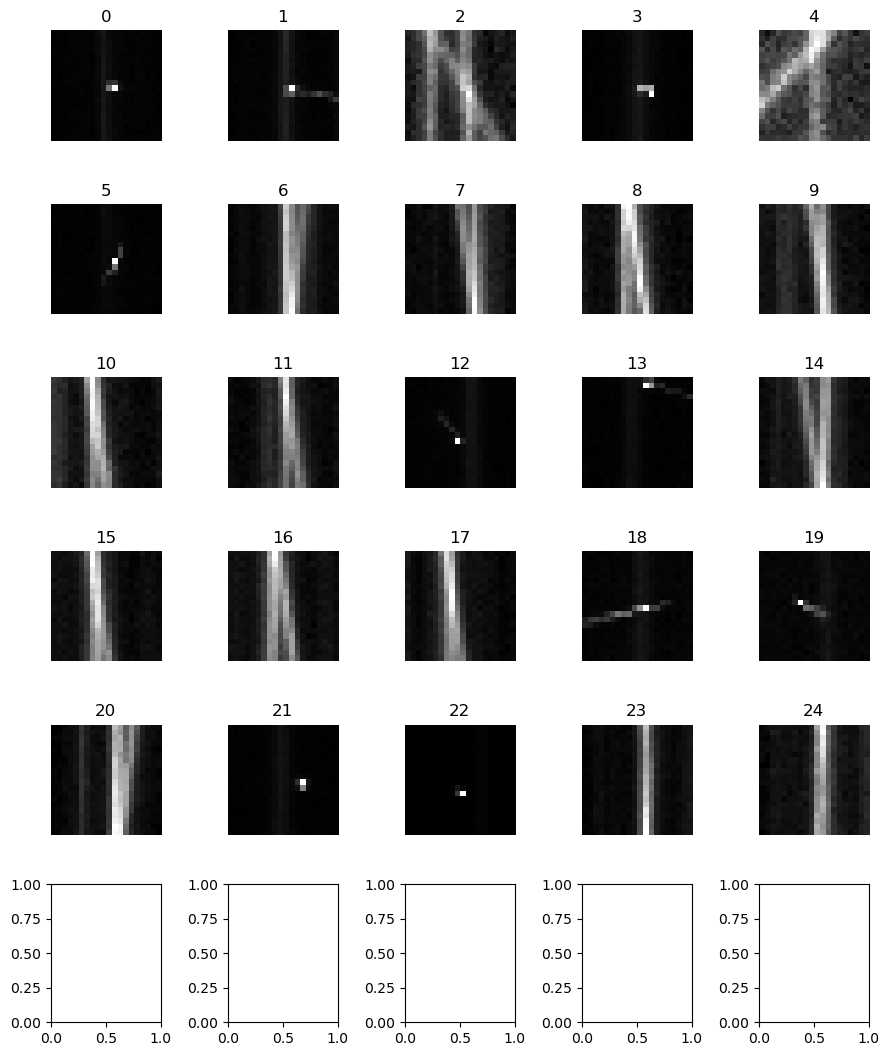

In [21]:
rff.inspect_df_w_stamp_color(brightening)

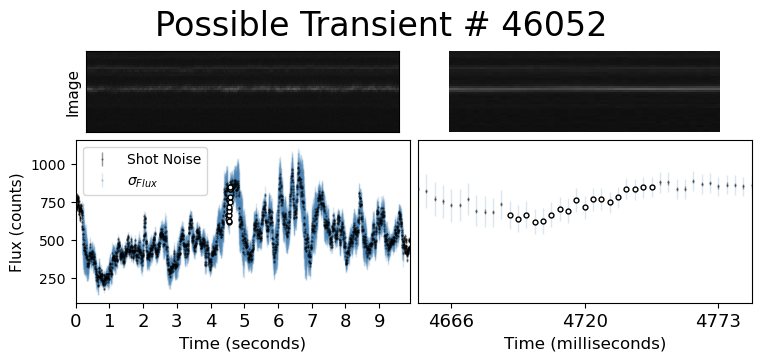

In [30]:
rff.plot_time_series_again_aperture(brightening, 46052)

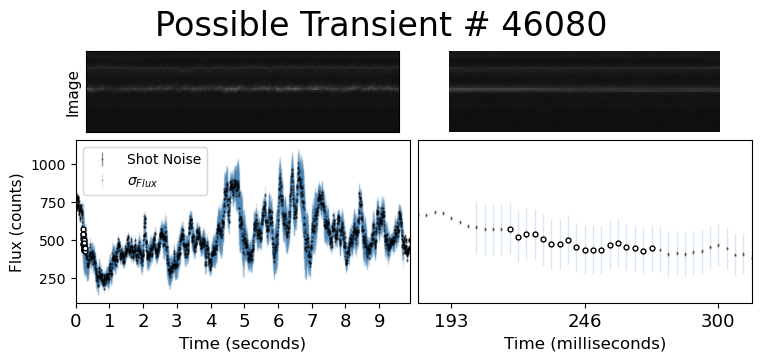

In [31]:
rff.plot_time_series_again_aperture(brightening, 46080)

In [ ]:
rff.plot_time_series_again_aperture(dimming, 41309)

In [206]:
dimming = concat2[concat2['snr_local_dimming']>2]

In [207]:
dimming

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,snr_global_dimming,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star
2587,2587,21,43,ztf_20221020141806_000686_zi_c14_x_0001.,1,pos,2394.363636,698.272727,11,708.0,...,1.720167,53.548647,93.062868,832.538788,-127.586029,108.0,160.083672,2399.0,1,33.0
5225,5225,8,26,ztf_20221020294271_000449_zr_c14_x_0001.,4,pos,1153.727273,914.909091,22,925.0,...,1.638408,37.025670,47.857005,1175.936435,-203.669528,33.0,78.409298,1156.0,4,13.0
7659,7659,215,150,ztf_20221020148032_000686_zg_c11_x_0029.,1,pos,1598.500000,2661.666667,6,2669.0,...,1.561878,34.001773,54.542223,620.928495,-114.447966,72.0,85.188293,1603.0,1,5.0
11417,11417,3,2,ztf_20221020141806_000686_zi_c01_x_0000.,1,both,39.971694,326.696219,182,337.0,...,7.132443,18.803764,19.669425,494.375380,-414.361982,45.0,140.291047,29.0,1,4.0
12427,12427,27,335,ztf_20221020148032_000686_zg_c04_x_0028.,2,pos,2611.000000,420.750000,8,432.0,...,1.678664,30.870734,42.047508,808.587653,-170.084967,34.0,70.583631,2627.0,2,1.0
14529,14529,0,224,ztf_20221020148032_000686_zg_c03_x_0028.,2,pos,3022.000000,142.500000,2,152.0,...,1.813086,13.045379,14.989863,260.953387,-61.811190,12.0,27.177910,3039.0,2,1.0
18641,18641,3,0,ztf_20221020141806_000686_zi_c01_x_0000.,2,pos,11.419580,112.517483,143,123.0,...,3.086603,32.070082,37.675741,1250.165779,-693.752449,20.0,116.290052,11.0,2,3.0
18657,18657,19,2,ztf_20221020141806_000686_zi_c01_x_0000.,2,pos,41.186207,1905.731034,145,1916.0,...,7.398592,18.444059,21.987278,673.847294,-385.853489,51.0,162.674904,42.0,2,1.0
21902,21902,1,0,ztf_20221020297847_000449_zr_c07_x_0000.,1,both,10.460784,1021.450980,38,1032.0,...,2.334702,18.455886,16.678624,503.959196,-233.516325,8.0,38.939614,2.0,1,1.0
22755,22755,18,15,ztf_20221020141806_000686_zi_c14_x_0001.,4,both,462.051724,696.870690,41,708.0,...,1.076833,53.027348,104.688455,560.916037,-200.147269,81.0,112.731958,455.0,4,63.0


In [209]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [211]:
rff.inspect_df_w_stamp_color?

Signature:
rff.inspect_df_w_stamp_color(
    df,
    imgsize=10,
    star=False,
    clim=None,
    plot='stamp',
    norm=False,
    titlecol=[],
    twodec=False,
)
Docstring:
plots the stamps corresponding to detections in a dataframe
no limit, so put in df[:100] or something probably to save time
File:      ~/rwe/review_findings_functions.py
Type:      function

In [213]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

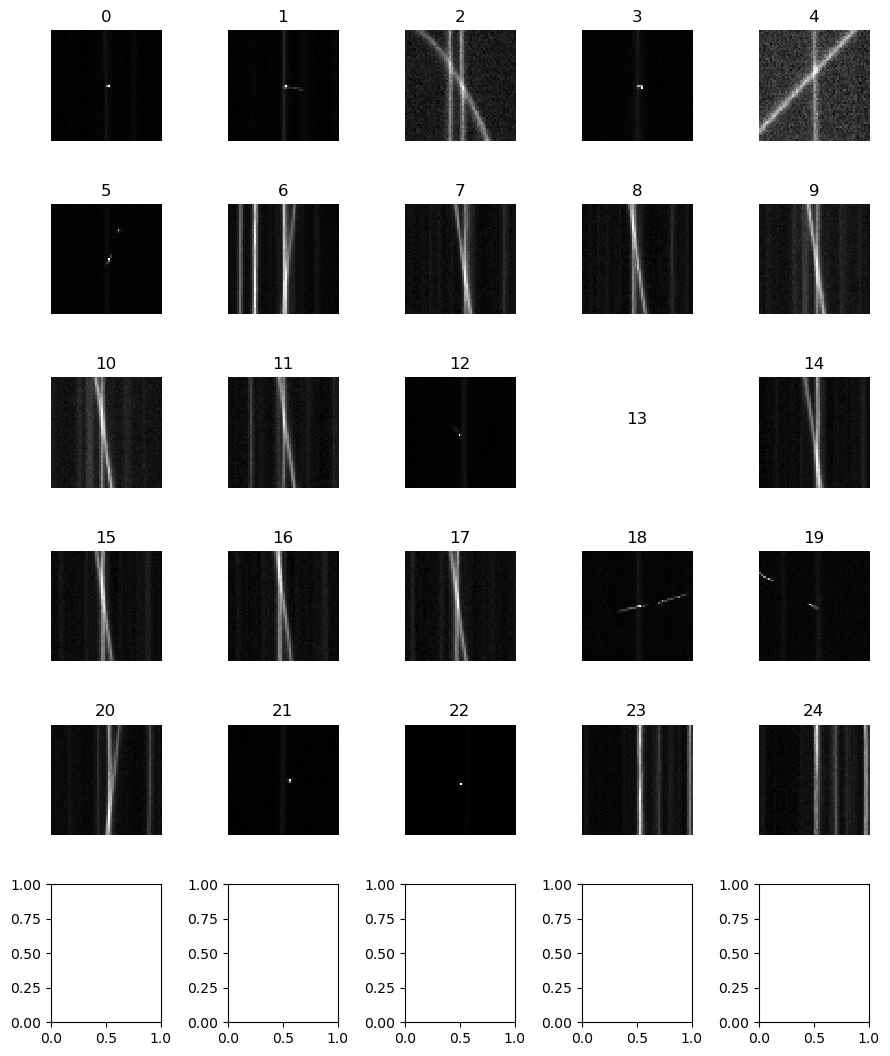

In [218]:
rff.inspect_df_w_stamp_color(brightening,imgsize=30)

In [219]:
dimming

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,snr_global_dimming,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star
2587,2587,21,43,ztf_20221020141806_000686_zi_c14_x_0001.,1,pos,2394.363636,698.272727,11,708.0,...,1.720167,53.548647,93.062868,832.538788,-127.586029,108.0,160.083672,2399.0,1,33.0
5225,5225,8,26,ztf_20221020294271_000449_zr_c14_x_0001.,4,pos,1153.727273,914.909091,22,925.0,...,1.638408,37.025670,47.857005,1175.936435,-203.669528,33.0,78.409298,1156.0,4,13.0
7659,7659,215,150,ztf_20221020148032_000686_zg_c11_x_0029.,1,pos,1598.500000,2661.666667,6,2669.0,...,1.561878,34.001773,54.542223,620.928495,-114.447966,72.0,85.188293,1603.0,1,5.0
11417,11417,3,2,ztf_20221020141806_000686_zi_c01_x_0000.,1,both,39.971694,326.696219,182,337.0,...,7.132443,18.803764,19.669425,494.375380,-414.361982,45.0,140.291047,29.0,1,4.0
12427,12427,27,335,ztf_20221020148032_000686_zg_c04_x_0028.,2,pos,2611.000000,420.750000,8,432.0,...,1.678664,30.870734,42.047508,808.587653,-170.084967,34.0,70.583631,2627.0,2,1.0
14529,14529,0,224,ztf_20221020148032_000686_zg_c03_x_0028.,2,pos,3022.000000,142.500000,2,152.0,...,1.813086,13.045379,14.989863,260.953387,-61.811190,12.0,27.177910,3039.0,2,1.0
18641,18641,3,0,ztf_20221020141806_000686_zi_c01_x_0000.,2,pos,11.419580,112.517483,143,123.0,...,3.086603,32.070082,37.675741,1250.165779,-693.752449,20.0,116.290052,11.0,2,3.0
18657,18657,19,2,ztf_20221020141806_000686_zi_c01_x_0000.,2,pos,41.186207,1905.731034,145,1916.0,...,7.398592,18.444059,21.987278,673.847294,-385.853489,51.0,162.674904,42.0,2,1.0
21902,21902,1,0,ztf_20221020297847_000449_zr_c07_x_0000.,1,both,10.460784,1021.450980,38,1032.0,...,2.334702,18.455886,16.678624,503.959196,-233.516325,8.0,38.939614,2.0,1,1.0
22755,22755,18,15,ztf_20221020141806_000686_zi_c14_x_0001.,4,both,462.051724,696.870690,41,708.0,...,1.076833,53.027348,104.688455,560.916037,-200.147269,81.0,112.731958,455.0,4,63.0


/home/3155/rwe/review_findings_functions.py:2379: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  return df


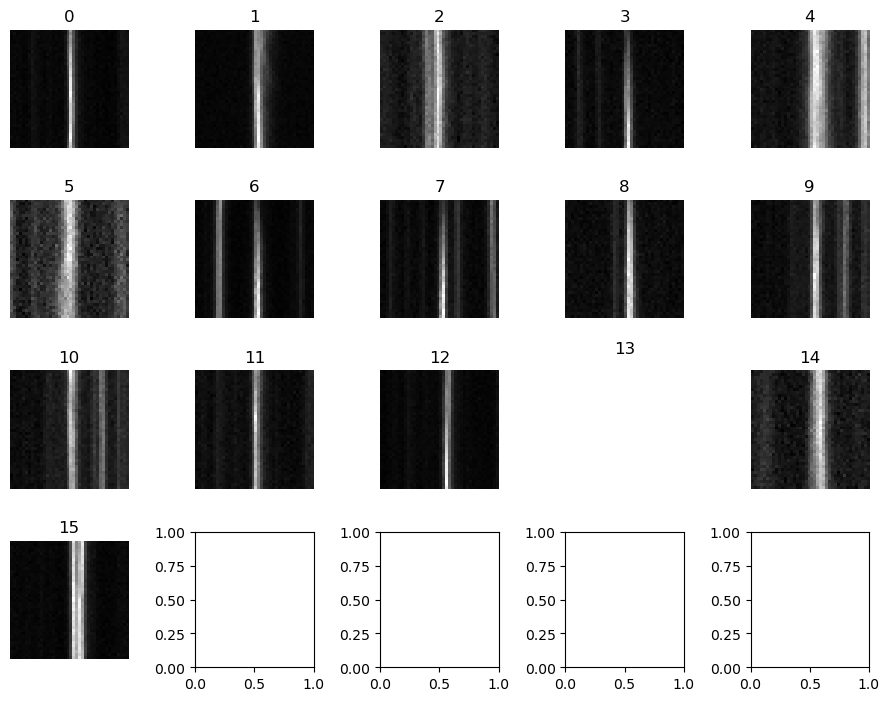

In [220]:
rff.inspect_df_w_stamp_color(dimming,imgsize=20)